In [ ]:
%pip install -q -U langchain-groq

In [ ]:
from google.colab import userdata
import os
os.environ['GROQ_API_KEY'] = userdata.get('GROQ_API_KEY')
print("Groq API key loaded successfully!")

Groq API key loaded successfully!


In [ ]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict


In [ ]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [ ]:
class BlogState(TypedDict):
  title:str
  outline:str
  content:str

In [ ]:
def create_outline(state:BlogState) -> BlogState:
  # fetch title
  title = state['title']
  # prompt
  prompt = f'Generate a detailed outline for a bolg on the topic - {title}'
  # call llm generate outline
  outline = model.invoke(prompt).content
  # update state
  state['outline'] = outline
  return state

In [ ]:
def create_blog(state:BlogState) -> BlogState:
  title = state['title']
  outline = state['outline']
  # prompt
  prompt = f'Write a detailed blog on the topic {title} using the following outline \n {outline}'
  content = model.invoke(prompt).content
  state['content'] = content
  return state

In [ ]:
# Define the graph
graph = StateGraph(BlogState)

# Define nodes
graph.add_node('create_outline',create_outline)
graph.add_node('create_blog',create_blog)

# Define edges
graph.add_edge(START,'create_outline')
graph.add_edge('create_outline','create_blog')
graph.add_edge('create_blog',END)

In [ ]:
# Compile the graph
workflow = graph.compile()

In [ ]:
initial_state = {'title':'Rise of AI jobs in India'}
final_state = workflow.invoke(initial_state)
print(final_state)

{'title': 'Rise of AI jobs in India', 'outline': '## Blog Outline  \n**Title:** *Rise of AI Jobs in India: Opportunities, Challenges, and the Road Ahead*  \n\n---\n\n### 1. Executive Summary (≈200\u202fwords)  \n- Quick snapshot of the AI job boom in India.  \n- Key statistics (e.g., projected growth, top sectors, skill gaps).  \n- Take‑away messages for readers (policy makers, job seekers, educators).  \n\n---\n\n### 2. Introduction (≈300\u202fwords)  \n- **Hook:** A striking anecdote or statistic (e.g., “India could add 5\u202fmillion AI jobs by 2030”).  \n- **Purpose:** Why this blog matters – the intersection of technology, employment, and economic growth.  \n- **Scope:** What readers will learn (trends, sectors, skills, policy, future outlook).  \n\n---\n\n### 3. Historical Context: AI in India (≈400\u202fwords)  \n| Timeframe | Milestones | Impact on Employment |\n|-----------|------------|----------------------|\n| 1990‑2000 | Early research labs, IIT initiatives | Niche R&D rol

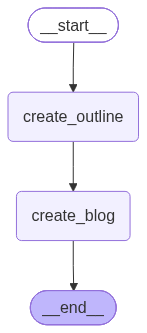

In [ ]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [ ]:
print(final_state['outline'])

## Blog Outline  
**Title:** *Rise of AI Jobs in India: Opportunities, Challenges, and the Road Ahead*  

---

### 1. Executive Summary (≈200 words)  
- Quick snapshot of the AI job boom in India.  
- Key statistics (e.g., projected growth, top sectors, skill gaps).  
- Take‑away messages for readers (policy makers, job seekers, educators).  

---

### 2. Introduction (≈300 words)  
- **Hook:** A striking anecdote or statistic (e.g., “India could add 5 million AI jobs by 2030”).  
- **Purpose:** Why this blog matters – the intersection of technology, employment, and economic growth.  
- **Scope:** What readers will learn (trends, sectors, skills, policy, future outlook).  

---

### 3. Historical Context: AI in India (≈400 words)  
| Timeframe | Milestones | Impact on Employment |
|-----------|------------|----------------------|
| 1990‑2000 | Early research labs, IIT initiatives | Niche R&D roles |
| 2000‑2010 | Startup wave, AI research grants | Small‑scale data science jobs |
| 2010

In [ ]:
print(final_state['content'])

# Rise of AI Jobs in India: Opportunities, Challenges, and the Road Ahead  

---

## 1. Executive Summary (≈200 words)  
India’s AI talent pipeline has shifted from a handful of research labs to a nationwide ecosystem that now accounts for **over 1.2 million AI‑related positions** (full‑time, contract, freelance) as of 2024. The sector is growing at a compound annual growth rate (CAGR) of **28 %** and is projected to reach **5 million** roles by 2030. The bulk of jobs cluster in Tier‑1 metros—Bengaluru, Hyderabad, Pune, and Delhi—yet emerging hubs such as Kolkata, Chennai, and Ahmedabad are closing the gap.  

Key statistics:  
- **Top sectors:** IT/ITES (32 %), FinTech (18 %), HealthTech (15 %), AgriTech (9 %), Manufacturing (7 %).  
- **Skill gap:** 60 % of employers report difficulty filling roles that require deep learning and MLOps expertise.  
- **Gender parity:** Women hold only **27 %** of AI roles, indicating a significant diversity gap.  

Take‑away messages:  
- **Policy mak

# THANKS